<a href="https://colab.research.google.com/github/Radi7002/utsprobstat_kel2_3TIE/blob/main/Statistika_Projek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

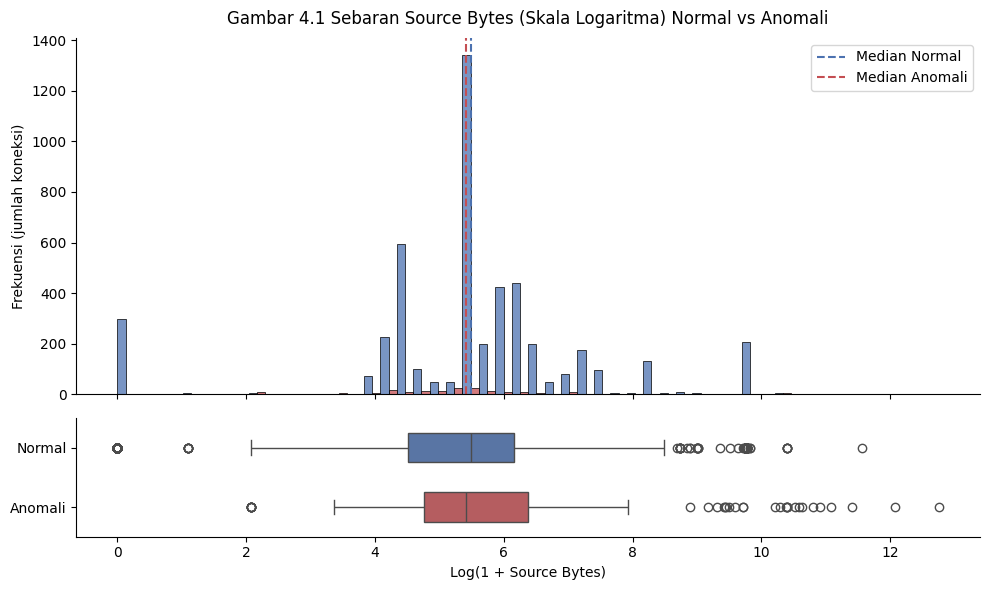

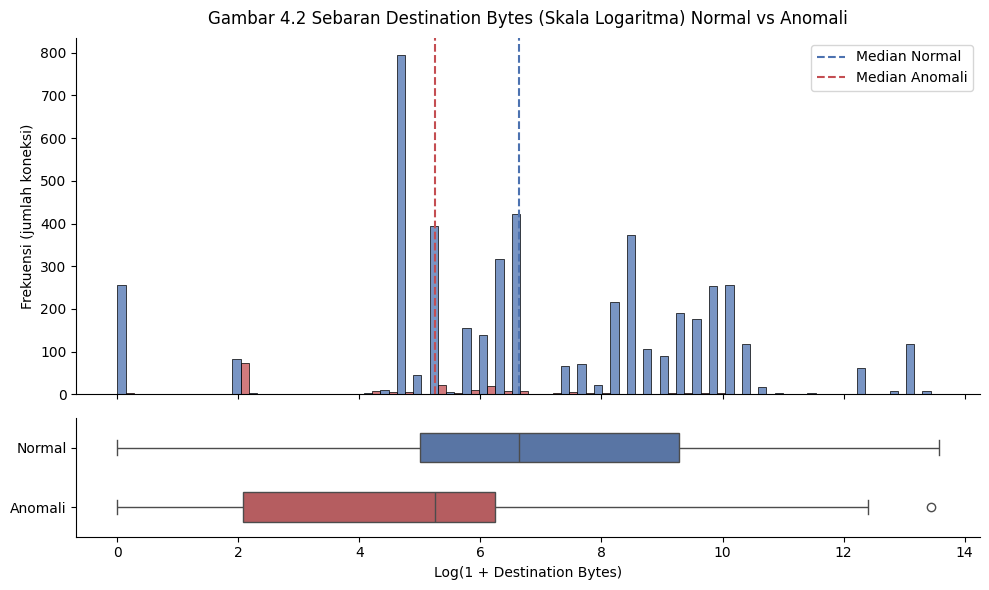

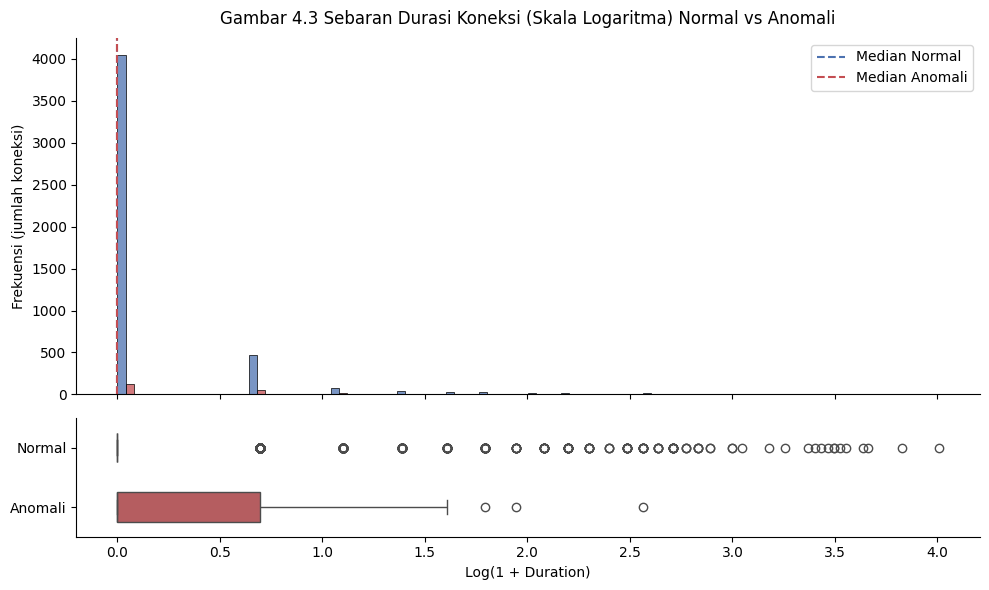

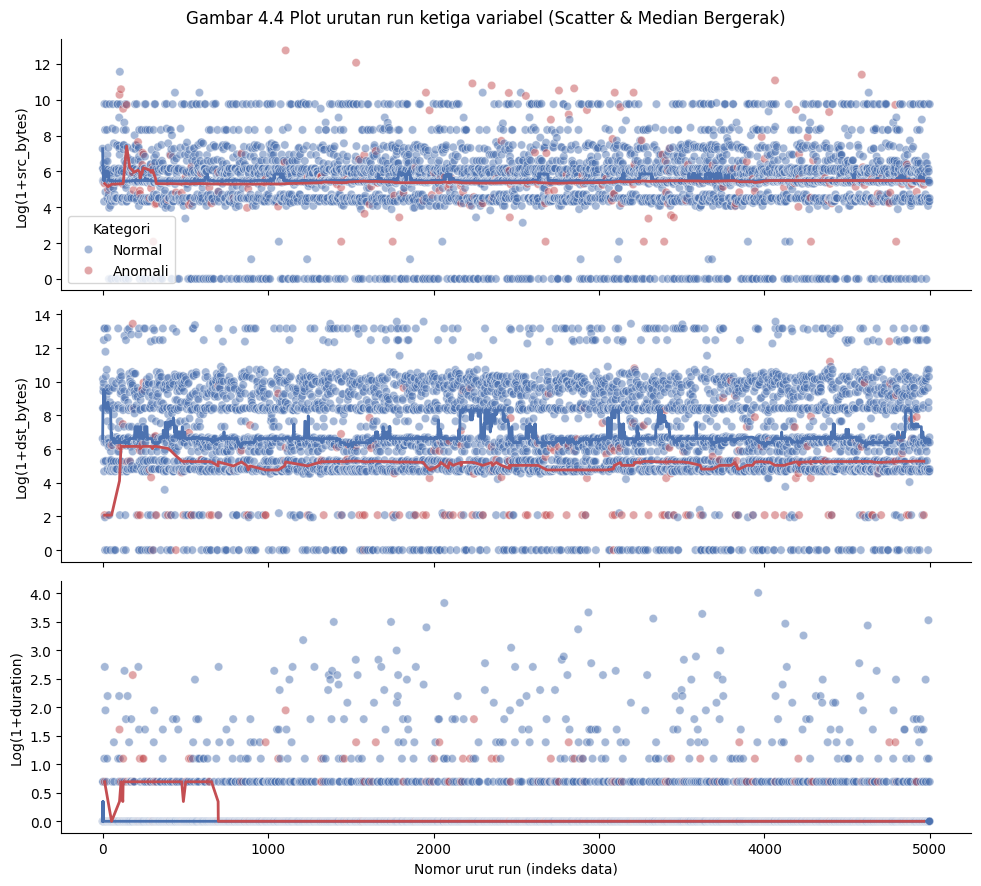

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') # Menghilangkan deprecation warnings

df = pd.read_csv('UNSW_Sample_5000.csv')

# Labeling
df['Kategori'] = df['label'].map({0: 'Normal', 1: 'Anomali'})

# Tranformasi Log1p (Logaritma natural 1 + x untuk meng-handle nilai 0)
df['src_bytes_log'] = np.log1p(df['src_bytes'])
df['dst_bytes_log'] = np.log1p(df['dst_bytes'])
df['duration_log'] = np.log1p(df['duration'])

def plot_distribusi(df, var_name, title, xlabel):
    fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": (.75, .25)})

    sns.histplot(data=df, x=var_name, hue='Kategori', multiple='dodge', bins=50, ax=ax_hist, palette={'Normal': '#4C72B0', 'Anomali': '#C44E52'})

    median_normal = df[df['Kategori']=='Normal'][var_name].median()
    median_anomali = df[df['Kategori']=='Anomali'][var_name].median()
    ax_hist.axvline(median_normal, color='#4C72B0', linestyle='--', label='Median Normal')
    ax_hist.axvline(median_anomali, color='#C44E52', linestyle='--', label='Median Anomali')

    ax_hist.set_title(title, pad=10)
    ax_hist.set_ylabel('Frekuensi (jumlah koneksi)')
    ax_hist.legend()

    sns.boxplot(data=df, x=var_name, y='Kategori', ax=ax_box, width=0.5, palette={'Normal': '#4C72B0', 'Anomali': '#C44E52'})
    ax_box.set_xlabel(xlabel)
    ax_box.set_ylabel('')

    sns.despine(ax=ax_hist)
    sns.despine(ax=ax_box)
    plt.tight_layout()
    plt.show()

# 1. Plot src_bytes
plot_distribusi(df, 'src_bytes_log', 'Gambar 4.1 Sebaran Source Bytes (Skala Logaritma) Normal vs Anomali', 'Log(1 + Source Bytes)')

# 2. Plot dst_bytes
plot_distribusi(df, 'dst_bytes_log', 'Gambar 4.2 Sebaran Destination Bytes (Skala Logaritma) Normal vs Anomali', 'Log(1 + Destination Bytes)')

# 3. Plot duration
plot_distribusi(df, 'duration_log', 'Gambar 4.3 Sebaran Durasi Koneksi (Skala Logaritma) Normal vs Anomali', 'Log(1 + Duration)')

# 4. Plot 4.4 Run Sequence (3 Axis)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
fig.suptitle('Gambar 4.4 Plot urutan run ketiga variabel (Scatter & Median Bergerak)')
variabel_log = ['src_bytes_log', 'dst_bytes_log', 'duration_log']
ylabels = ['Log(1+src_bytes)', 'Log(1+dst_bytes)', 'Log(1+duration)']

for i, var in enumerate(variabel_log):
    sns.scatterplot(data=df, x=df.index, y=var, hue='Kategori', alpha=0.5, ax=axes[i], legend=(i==0), palette={'Normal': '#4C72B0', 'Anomali': '#C44E52'})

    for cat, warna in zip(['Normal', 'Anomali'], ['#4C72B0', '#C44E52']):
        subset = df[df['Kategori'] == cat]
        rolling_med = subset[var].rolling(window=100, min_periods=1).median()
        axes[i].plot(subset.index, rolling_med, color=warna, linewidth=2)

    axes[i].set_ylabel(ylabels[i])

axes[2].set_xlabel('Nomor urut run (indeks data)')
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Membaca dataset asli
print("Membaca dataset asli...")
df = pd.read_csv('UNSW_Pcap_KDD_features.csv')

# 2. Cek nama kolom untuk memastikan nama kolom label/jenis serangan
# Biasanya bernama 'label', 'Attack', 'attack_cat', atau sejenisnya
print("\nLima nama kolom terakhir:")
print(df.columns[-5:].tolist())

# GANTI 'label' dengan nama kolom yang berisi kategori serangan berdasarkan output di atas
kolom_target = 'label'

# 3. Melakukan Stratified Random Sampling (Mengambil 5000 baris)
# Parameter 'stratify' menjaga probabilitas/distribusi data tetap sama dengan aslinya
df_sample, _ = train_test_split(df,
                                train_size=5000,
                                random_state=42, # Menjaga agar hasil random tidak berubah jika di-run ulang
                                stratify=df[kolom_target])

# 4. Menyimpan dataset yang sudah disampel ke CSV baru
nama_file_baru = 'UNSW_Sample_5000.csv'
df_sample.to_csv(nama_file_baru, index=False)

# 5. Menampilkan hasil validasi statistika
print(f"\nBerhasil membuat sampel! Jumlah baris saat ini: {len(df_sample)}")
print(f"Data sampel telah disimpan dengan nama: {nama_file_baru}")

print(f"\nProporsi distribusi serangan pada 5000 data sampel:")
print(df_sample[kolom_target].value_counts(normalize=True) * 100)